# Credit Card Customer Churn & Retention Analytics
## Exploratory Data Analysis (EDA)

### Business Context
Customer churn is an important challenge in the credit card industry, as losing existing customers can affect revenue, customer lifetime value, and long-term profitability.

This project analyzes customer demographic characteristics, financial behavior, transaction activity, and engagement patterns to better understand customer churn and identify potential retention opportunities.

### Business Objectives

## 1. Environment Setup

In [ ]:
%pip install matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Data Understanding

### Objective
Examine the structure, dimensions, and characteristics of the dataset before conducting further analysis.

In [6]:
import pandas as pd

df = pd.read_csv("../data/raw/credit_card_customer_churn_dataset.csv")

print(df.shape)
df.head()

(100000, 40)


,customer_id,age,gender,marital_status,education_level,employment_status,income,city,credit_score,account_age_months,card_type,credit_limit,annual_fee,interest_rate,num_products,has_loan,has_savings_account,monthly_spending,avg_transaction_amount,monthly_transactions,online_transactions,international_transactions,cash_withdrawals,utilization_ratio,payment_delay_count,late_payment_amount,app_logins_monthly,website_visits_monthly,customer_service_calls,complaints_count,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned
0,CUST-0000001,50,Male,Divorced,Bachelor,Employed,"31,679.55",San Diego,685,151,Standard,"1,100.00",0,16.46,3,0,1,569.99,114.00,5,1,0,1,0.54,1,23.09,8,4,1,0,4.10,728,3,1,50.33,74.89,54.35,13.00,0.13,0
1,CUST-0000002,42,Female,Married,Bachelor,Self-Employed,"83,618.66",Los Angeles,732,81,Gold,"29,600.00",150,18.24,1,0,1,"14,288.14",118.08,121,82,11,0,0.47,0,0.00,20,5,0,0,3.30,13537,3,2,17.70,85.36,99.34,4.30,0.04,0
2,CUST-0000003,52,Male,Married,Bachelor,Self-Employed,"134,295.30",Phoenix,777,41,Standard,"15,300.00",0,12.37,2,0,1,"5,222.78",121.46,43,18,0,0,0.36,0,0.00,12,3,1,0,3.20,4671,4,2,15.67,74.81,30.56,3.32,0.03,0
3,CUST-0000004,63,Female,Married,Bachelor,Employed,"100,983.46",New York,708,54,Gold,"39,800.00",150,14.93,1,0,0,"8,835.64",68.49,129,84,11,0,0.22,0,0.00,10,3,0,0,3.10,12694,4,0,13.13,47.55,80.07,19.30,0.19,0
4,CUST-0000005,40,Male,Married,Bachelor,Employed,"89,736.89",Other,664,95,Gold,"34,300.00",150,18.11,1,0,1,"31,261.45",208.41,150,86,4,0,0.88,0,0.00,12,5,1,0,4.50,37007,1,1,44.25,58.71,100.00,15.10,0.15,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   customer_id                 100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   marital_status              100000 non-null  str    
 4   education_level             100000 non-null  str    
 5   employment_status           100000 non-null  str    
 6   income                      100000 non-null  float64
 7   city                        100000 non-null  str    
 8   credit_score                100000 non-null  int64  
 9   account_age_months          100000 non-null  int64  
 10  card_type                   100000 non-null  str    
 11  credit_limit                100000 non-null  float64
 12  annual_fee                  100000 non-null  int64  
 13  interest_rate             

In [ ]:
df.columns.tolist()

In [ ]:
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())

## 3. Data Quality Assessment

In [8]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_values = missing_values.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_values)

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Count,Missing Percentage
customer_id,0,0.00
age,0,0.00
gender,0,0.00
marital_status,0,0.00
education_level,0,0.00
employment_status,0,0.00
income,0,0.00
city,0,0.00
credit_score,0,0.00
account_age_months,0,0.00


Total Missing Values: 0


In [9]:
print("Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Customer IDs:",
    df["customer_id"].duplicated().sum()
)

print(
    "Unique Customers:",
    df["customer_id"].nunique()
)

Duplicate Rows: 0
Duplicate Customer IDs: 0
Unique Customers: 100000


In [ ]:
validation_checks = {
    "Unique Customer IDs":
        df["customer_id"].is_unique,

    "No Missing Customer IDs":
        df["customer_id"].notnull().all(),

    "Valid Churn Values":
        df["churned"].isin([0, 1]).all(),

    "Valid Credit Scores":
        df["credit_score"].between(300, 850).all(),

    "Valid Utilization Ratio":
        df["utilization_ratio"].between(0, 1).all(),

    "Non-negative Income":
        (df["income"] >= 0).all(),

    "Non-negative Monthly Spending":
        (df["monthly_spending"] >= 0).all()
}

validation_results = pd.DataFrame(
    validation_checks.items(),
    columns=["Validation Check", "Passed"]
)

display(validation_results)

## 4. Descriptive Statistics

In [ ]:
df.describe().T

In [ ]:
selected_features = [
    "age",
    "income",
    "credit_score",
    "account_age_months",
    "monthly_spending",
    "utilization_ratio"
]

summary_stats = df[selected_features].agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

display(summary_stats)

## 5. Univariate Analysis

### Objective
Understand the distributions of individual customer characteristics and financial variables.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

features = [
    "age",
    "income",
    "credit_score",
    "account_age_months",
    "monthly_spending",
    "utilization_ratio"
]

for ax, feature in zip(axes.flatten(), features):

    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        color="#2563EB",
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Customers")

plt.suptitle(
    "Customer Demographic and Financial Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="income",
    color="#2563EB",
    ax=axes[0]
)

axes[0].set_title("Income Distribution")

sns.boxplot(
    data=df,
    x="monthly_spending",
    color="#F97316",
    ax=axes[1]
)

axes[1].set_title("Monthly Spending Distribution")

plt.tight_layout()
plt.show()

## 6. Customer Churn Overview

### Business Question
What percentage of credit card customers have churned?

In [ ]:
total_customers = len(df)

churned_customers = df["churned"].sum()

retained_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100

retention_rate = 100 - churn_rate

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

In [ ]:
churn_counts = (
    df["churned"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Retained", "Churned"],
    churn_counts.values,
    color=["#2563EB", "#F97316"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1000,
        f"{height:,.0f}\n({height / total_customers:.1%})",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Credit Card Customer Churn Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Number of Customers")
ax.set_ylim(0, max(churn_counts.values) * 1.15)

sns.despine()
plt.tight_layout()
plt.show()

## 7. Customer Segmentation Analysis

In [10]:
card_churn = (
    df.groupby("card_type")
    .agg(
        total_customers=("customer_id", "count"),
        churned_customers=("churned", "sum"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

card_churn["churn_rate"] *= 100

card_churn = card_churn.sort_values(
    "churn_rate",
    ascending=False
)

display(card_churn)

,card_type,total_customers,churned_customers,churn_rate
3,Standard,45048,8849,19.64
2,Silver,29768,5785,19.43
0,Gold,18061,3476,19.25
1,Platinum,7123,1348,18.92


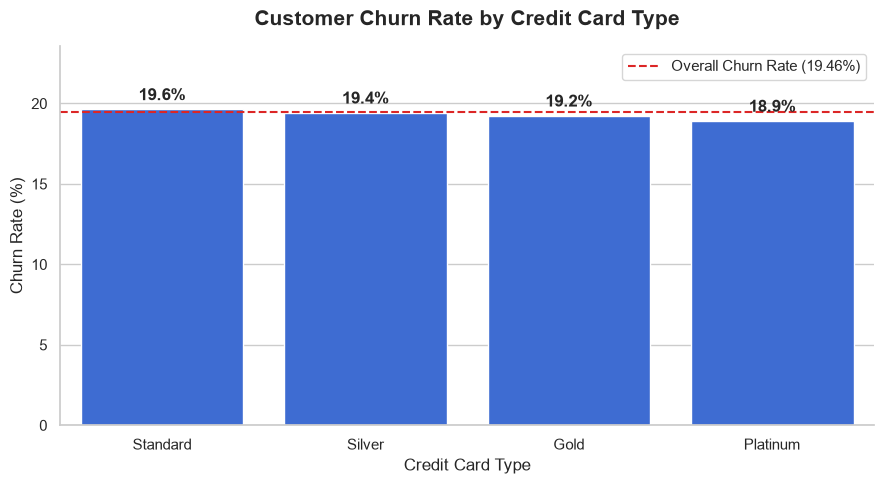

In [14]:
# Calculate overall churn rate
churn_rate = df["churned"].mean() * 100

# Create visualization
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=card_churn,
    x="card_type",
    y="churn_rate",
    color="#2563EB"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontweight="bold"
    )

# Overall churn baseline
plt.axhline(
    y=churn_rate,
    color="#DC2626",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall Churn Rate ({churn_rate:.2f}%)"
)

plt.title(
    "Customer Churn Rate by Credit Card Type",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Credit Card Type")
plt.ylabel("Churn Rate (%)")

plt.ylim(
    0,
    max(card_churn["churn_rate"].max(), churn_rate) * 1.2
)

plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

## 8. Behavioral Analysis — Complaints and Payment Delays

In [15]:
complaints_analysis = (
    df.assign(
        complaint_group=df["complaints_count"].clip(upper=5)
    )
    .groupby("complaint_group")
    .agg(
        total_customers=("customer_id", "count"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

complaints_analysis["churn_rate"] *= 100

complaints_analysis["complaint_group"] = (
    complaints_analysis["complaint_group"]
    .astype(str)
    .replace({"5": "5+"})
)

display(complaints_analysis)

,complaint_group,total_customers,churn_rate
0,0,62355,13.76
1,1,23439,22.18
2,2,8760,32.64
3,3,3407,45.05
4,4,1320,57.42
5,5+,719,72.88


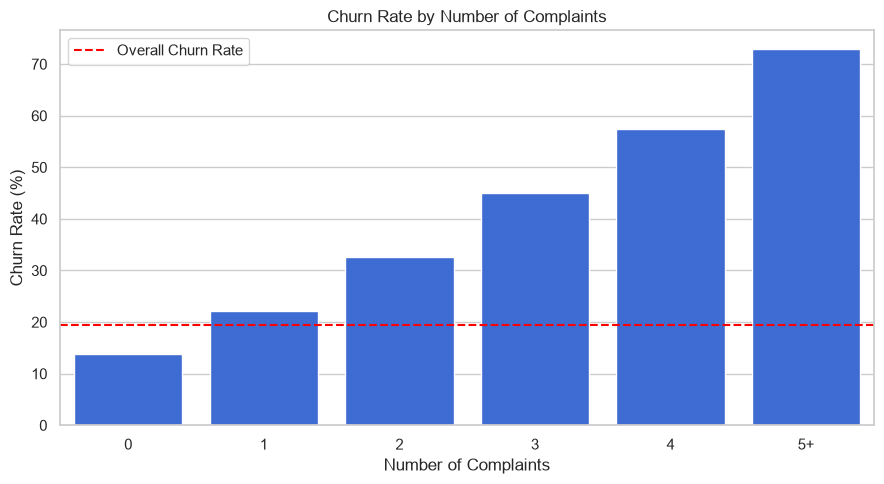

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=complaints_analysis,
    x="complaint_group",
    y="churn_rate",
    color="#2563EB"
)

plt.axhline(
    churn_rate,
    color="red",
    linestyle="--",
    label="Overall Churn Rate"
)

plt.title("Churn Rate by Number of Complaints")

plt.xlabel("Number of Complaints")
plt.ylabel("Churn Rate (%)")

plt.legend()
plt.tight_layout()
plt.show()

,delay_group,total_customers,churn_rate
0,0,70059,12.46
1,1,20785,27.04
2,2,6496,47.52
3,3,1871,70.39
4,4,546,86.81
5,5+,243,95.06


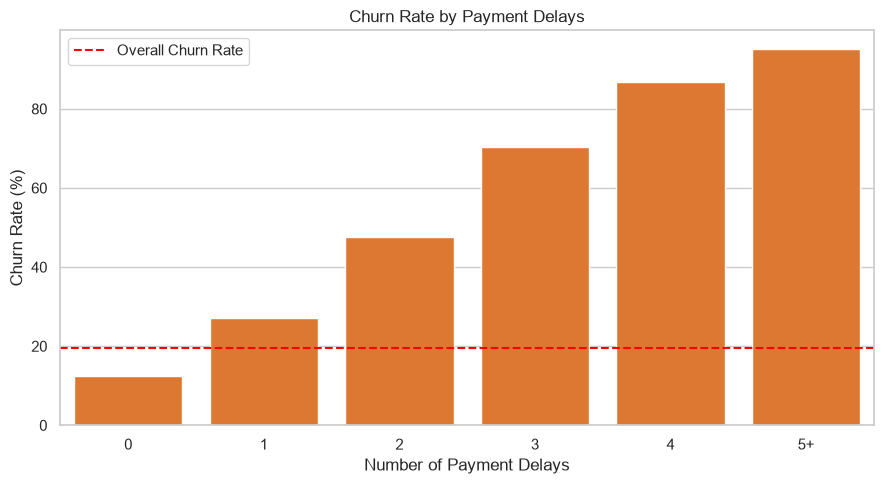

In [18]:
payment_analysis = (
    df.assign(
        delay_group=df["payment_delay_count"].clip(upper=5)
    )
    .groupby("delay_group")
    .agg(
        total_customers=("customer_id", "count"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

payment_analysis["churn_rate"] *= 100

payment_analysis["delay_group"] = (
    payment_analysis["delay_group"]
    .astype(str)
    .replace({"5": "5+"})
)

display(payment_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_analysis,
    x="delay_group",
    y="churn_rate",
    color="#F97316"
)

plt.axhline(
    churn_rate,
    color="red",
    linestyle="--",
    label="Overall Churn Rate"
)

plt.title("Churn Rate by Payment Delays")
plt.xlabel("Number of Payment Delays")
plt.ylabel("Churn Rate (%)")

plt.legend()
plt.tight_layout()
plt.show()

## 9. Customer Engagement Analysis

### Business Question
Are lower digital engagement and limited product usage associated with customer churn?

,app_activity_group,total_customers,churn_rate
0,"(0.999, 10.0]",34758,23.57
1,"(10.0, 12.0]",22773,19.36
2,"(12.0, 14.0]",19583,17.71
3,"(14.0, 28.0]",22886,14.81


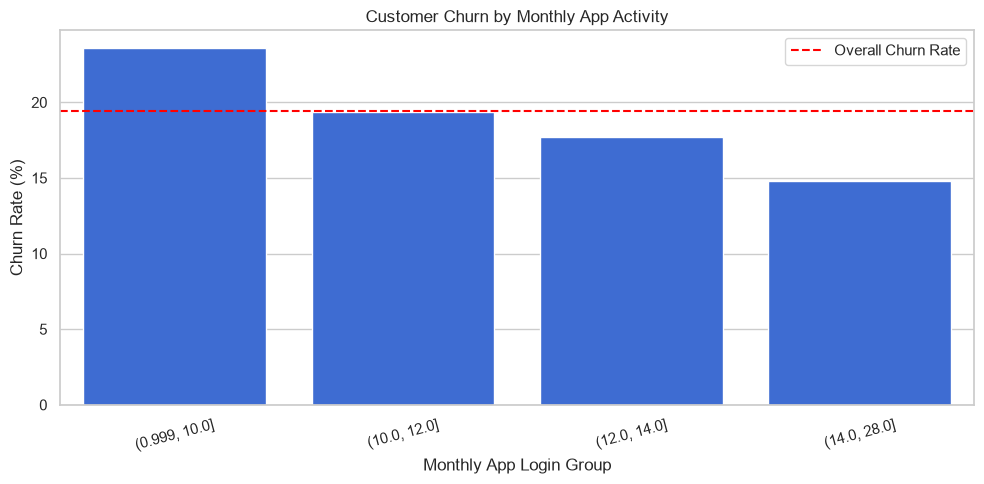

In [19]:
df_eda = df.copy()

df_eda["app_activity_group"] = pd.qcut(
    df_eda["app_logins_monthly"],
    q=4,
    duplicates="drop"
)

app_analysis = (
    df_eda.groupby("app_activity_group", observed=True)
    .agg(
        total_customers=("customer_id", "count"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

app_analysis["churn_rate"] *= 100

display(app_analysis)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=app_analysis,
    x="app_activity_group",
    y="churn_rate",
    color="#2563EB"
)

plt.axhline(
    churn_rate,
    color="red",
    linestyle="--",
    label="Overall Churn Rate"
)

plt.title("Customer Churn by Monthly App Activity")
plt.xlabel("Monthly App Login Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.legend()
plt.tight_layout()
plt.show()

,num_products,total_customers,churn_rate
0,1,45035,25.90
1,2,34992,16.75
2,3,15040,10.75
3,4,4933,6.37


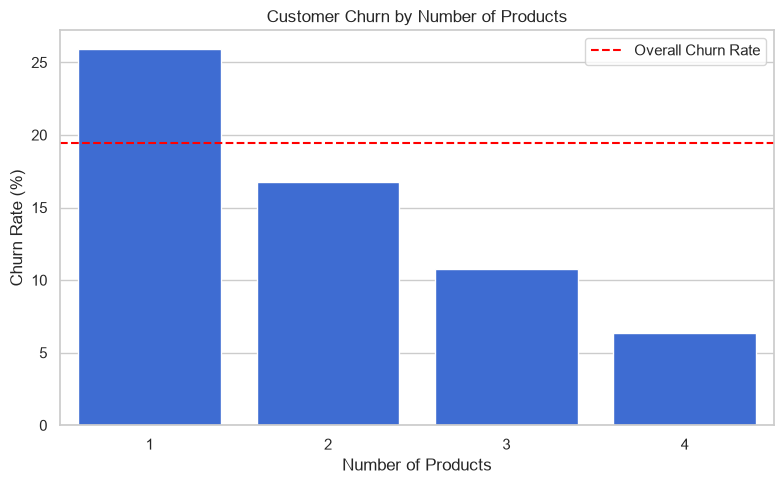

In [21]:
product_analysis = (
    df.groupby("num_products")
    .agg(
        total_customers=("customer_id", "count"),
        churn_rate=("churned", "mean")
    )
    .reset_index()
)

product_analysis["churn_rate"] *= 100

display(product_analysis)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=product_analysis,
    x="num_products",
    y="churn_rate",
    color="#2563EB"
)

plt.axhline(
    churn_rate,
    color="red",
    linestyle="--",
    label="Overall Churn Rate"
)

plt.title("Customer Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

plt.legend()
plt.tight_layout()
plt.show()

## 10. Correlation Analysis

### Objective
Examine linear relationships between selected numerical variables and customer churn.

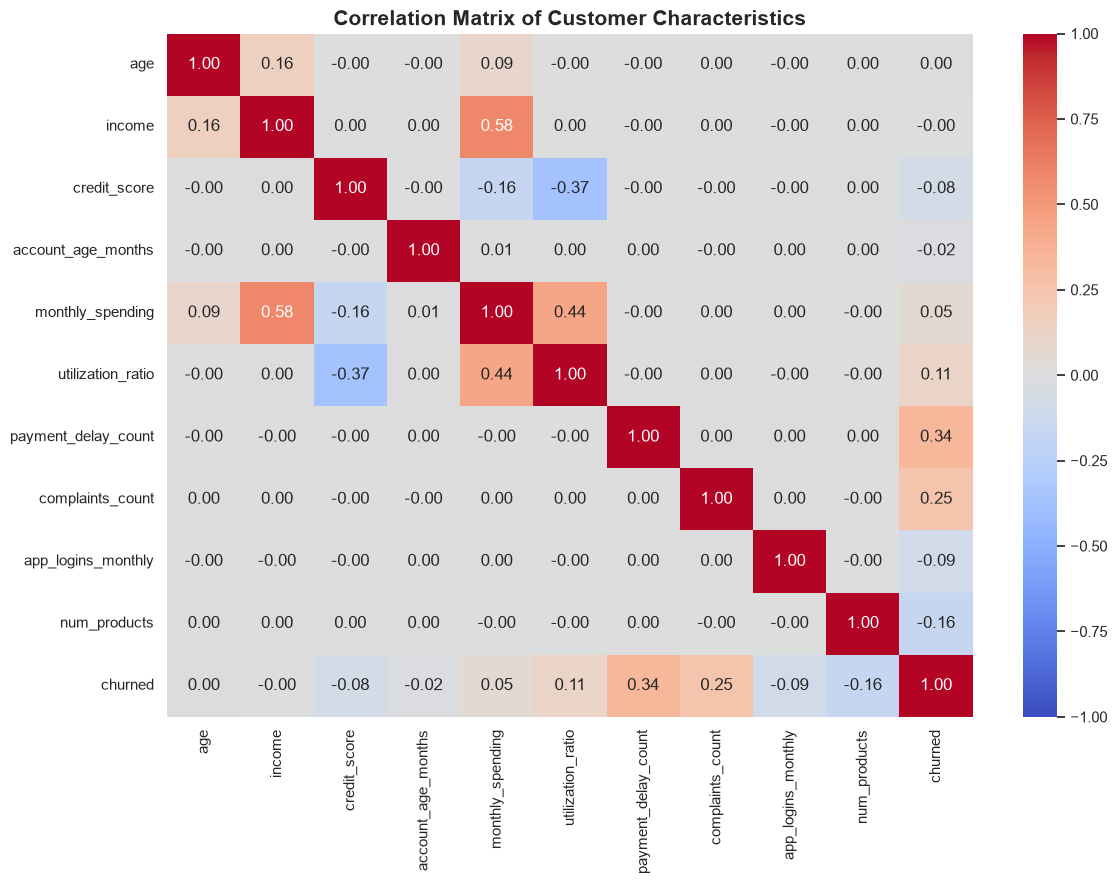

In [22]:
correlation_features = [
    "age",
    "income",
    "credit_score",
    "account_age_months",
    "monthly_spending",
    "utilization_ratio",
    "payment_delay_count",
    "complaints_count",
    "app_logins_monthly",
    "num_products",
    "churned"
]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Matrix of Customer Characteristics",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [23]:
churn_correlations = (
    correlation_matrix["churned"]
    .drop("churned")
    .sort_values(key=abs, ascending=False)
)

display(
    churn_correlations.to_frame(
        name="Correlation with Churn"
    )
)

,Correlation with Churn
payment_delay_count,0.34
complaints_count,0.25
num_products,-0.16
utilization_ratio,0.11
app_logins_monthly,-0.09
credit_score,-0.08
monthly_spending,0.05
account_age_months,-0.02
income,-0.00
age,0.00
